# PVD公开实验数据：描述性统计与可视化

本Notebook分析通过第一轮质量检查的30条实验记录。图表按材料及论文来源呈现；不同论文使用的材料、设备、气体和测量方法不同，因此不把跨论文的差异解释为单一工艺参数的作用。9条存疑记录不参与计算。

运行环境：Ubuntu/WSL 中的 `Python (PVD Course)` 内核。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

def locate_data_file():
    filename = 'pvd_experiments_verified_v3.csv'
    start = Path.cwd().resolve()
    for root in [start, *start.parents]:
        for path in [
            root / filename,
            root / 'outputs' / 'pvd_public_data_v3' / filename,
            root / '项目名' / 'outputs' / 'pvd_public_data_v3' / filename,
        ]:
            if path.is_file():
                return path
    raise FileNotFoundError(f'未找到 {filename}。请从课程项目目录打开Notebook。')

data_path = locate_data_file()
output_dir = data_path.parent / 'eda'
output_dir.mkdir(parents=True, exist_ok=True)
print('数据文件：', data_path)
print('图表与统计输出：', output_dir)

数据文件： /mnt/d/学业/项目名/outputs/pvd_public_data_v3/pvd_experiments_verified_v3.csv
图表与统计输出： /mnt/d/学业/项目名/outputs/pvd_public_data_v3/eda


## 1. 读取主数据并确认分析范围

本单元格检查记录数、编号唯一性和核验状态。后续绘图仅使用这份主数据。

In [2]:
df = pd.read_csv(data_path)
assert len(df) == 30, f'预期30条记录，实际{len(df)}条'
assert df['experiment_id'].is_unique, '实验编号存在重复'
assert df['verification_status'].eq('verified').all(), '主表含未经核实记录'
assert df['thickness_status'].eq('reported_measured').all(), '主表含非直接测量膜厚'
assert df[['deposition_time_min', 'pressure_Pa', 'film_thickness_nm']].notna().all().all()

# 平均沉积速率是根据膜厚和沉积时间计算，区别于论文可能另行报告的速率。
df['calculated_rate_nm_min'] = df['film_thickness_nm'] / df['deposition_time_min']
print(f'进入分析：{len(df)}条记录，{df.source_id.nunique()}篇论文，{df.target_material.nunique()}种材料')
display(df[['experiment_id', 'source_id', 'target_material', 'deposition_time_min', 'pressure_Pa', 'power_W', 'discharge_current_mA', 'film_thickness_nm', 'calculated_rate_nm_min']].head())

进入分析：30条记录，4篇论文，4种材料


,experiment_id,source_id,target_material,deposition_time_min,pressure_Pa,power_W,discharge_current_mA,film_thickness_nm,calculated_rate_nm_min
0,CU3N-01,S02,Cu3N,30,3.5,25.0,NaN,45.0,1.500000
1,CU3N-02,S02,Cu3N,30,3.5,50.0,NaN,85.0,2.833333
2,CU3N-03,S02,Cu3N,15,3.5,75.0,NaN,95.0,6.333333
3,CU3N-04,S02,Cu3N,15,3.5,100.0,NaN,100.0,6.666667
4,CU3N-05,S02,Cu3N,10,3.5,150.0,NaN,175.0,17.500000


## 2. 按材料和论文来源汇总

膜厚用最小值、中位数和最大值概括。单条记录的组不计算标准差。这里的统计只描述数据范围，不用于比较材料优劣。

In [3]:
summary = (
    df.groupby(['target_material', 'source_id'], as_index=False)
      .agg(records=('experiment_id', 'size'),
           time_min=('deposition_time_min', 'min'),
           time_max=('deposition_time_min', 'max'),
           pressure_min_Pa=('pressure_Pa', 'min'),
           pressure_max_Pa=('pressure_Pa', 'max'),
           thickness_min_nm=('film_thickness_nm', 'min'),
           thickness_median_nm=('film_thickness_nm', 'median'),
           thickness_max_nm=('film_thickness_nm', 'max'),
           calculated_rate_median_nm_min=('calculated_rate_nm_min', 'median'),
           power_records=('power_W', 'count'),
           current_records=('discharge_current_mA', 'count'))
      .sort_values('target_material')
)
summary.to_csv(output_dir / 'descriptive_summary_by_material.csv', index=False, encoding='utf-8-sig')
display(summary.round(2))
print('四组记录数合计：', int(summary.records.sum()))

,target_material,source_id,records,time_min,time_max,pressure_min_Pa,pressure_max_Pa,thickness_min_nm,thickness_median_nm,thickness_max_nm,calculated_rate_median_nm_min,power_records,current_records
0,Cu3N,S02,12,7,30,3.5,5.0,40.0,97.50,215.0,6.50,12,0
1,Pt,S01,8,2,12,0.5,1.5,41.5,143.55,428.4,28.45,0,8
2,Ti,S05,9,30,30,0.5,1.5,820.0,1030.00,1210.0,34.33,9,0
3,W,S03,1,8,8,0.2,0.2,79.7,79.70,79.7,9.96,1,0


四组记录数合计： 30


## 3. 数据构成与膜厚范围

左图显示各材料的记录数；右图显示每条实测膜厚。膜厚纵轴采用对数刻度，以便在同一图中显示40–1210 nm的范围。W只有1条记录，不能推断其分布。

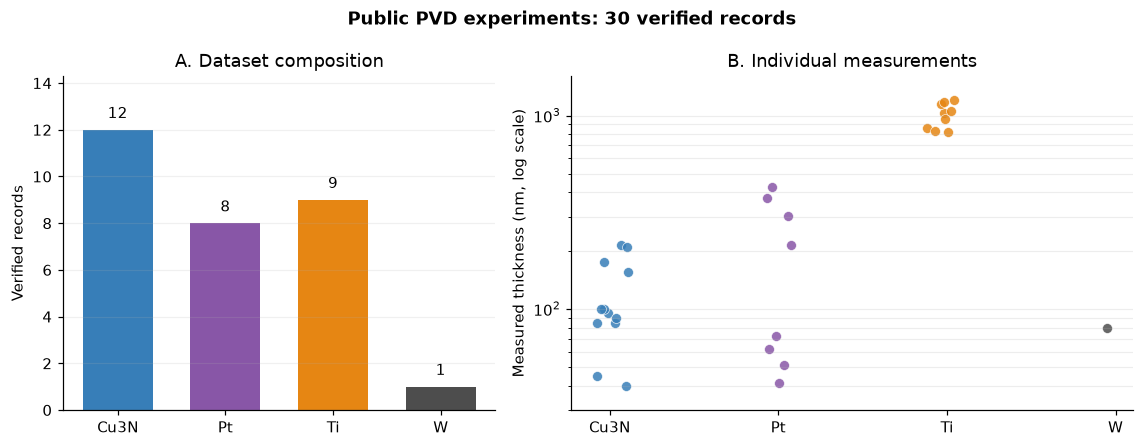

In [4]:
material_order = ['Cu3N', 'Pt', 'Ti', 'W']
colors = {'Cu3N': '#377eb8', 'Pt': '#8856a7', 'Ti': '#e68613', 'W': '#4d4d4d'}
counts = df.target_material.value_counts().reindex(material_order, fill_value=0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.1), gridspec_kw={'width_ratios': [1, 1.3]})
ax1.bar(material_order, counts.values, color=[colors[m] for m in material_order], width=0.65)
for i, n in enumerate(counts.values):
    ax1.text(i, n + 0.35, str(n), ha='center', va='bottom')
ax1.set_ylim(0, max(counts.values) + 2.3)
ax1.set_ylabel('Verified records')
ax1.set_title('A. Dataset composition')
ax1.grid(axis='y', alpha=0.18)

rng = np.random.default_rng(2026)
for i, material in enumerate(material_order):
    values = df.loc[df.target_material.eq(material), 'film_thickness_nm'].to_numpy()
    jitter = rng.uniform(-0.12, 0.12, size=len(values))
    ax2.scatter(np.full(len(values), i) + jitter, values, s=42, color=colors[material], alpha=0.85, edgecolor='white', linewidth=0.45)
ax2.set_xticks(range(len(material_order)), material_order)
ax2.set_yscale('log')
ax2.set_ylim(30, 1600)
ax2.set_ylabel('Measured thickness (nm, log scale)')
ax2.set_title('B. Individual measurements')
ax2.grid(axis='y', alpha=0.22, which='both')
fig.suptitle('Public PVD experiments: 30 verified records', fontsize=12, fontweight='bold')
fig.tight_layout()
fig.savefig(output_dir / '01_composition_and_thickness.png', bbox_inches='tight')
plt.show()

## 4. Ti：相同沉积时间下，功率与工作压力对应的膜厚

Ti组来自同一论文的9种参数组合，沉积时间均为30 min。热图中的数字为原论文报告的实测膜厚（nm），没有插值或模型预测。

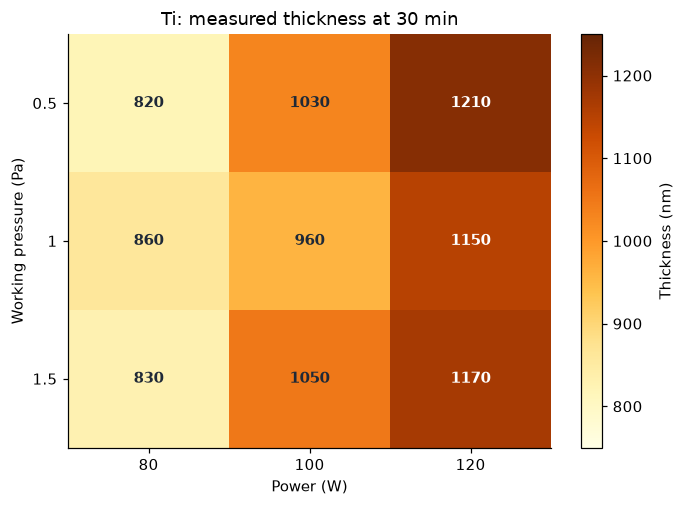

In [5]:
ti = df.loc[df.target_material.eq('Ti')].copy()
ti_grid = ti.pivot(index='pressure_Pa', columns='power_W', values='film_thickness_nm').sort_index().sort_index(axis=1)
assert ti_grid.shape == (3, 3) and ti_grid.notna().all().all()
fig, ax = plt.subplots(figsize=(6.4, 4.7))
im = ax.imshow(ti_grid.values, cmap='YlOrBr', aspect='auto', vmin=750, vmax=1250)
ax.set_xticks(range(len(ti_grid.columns)), [f'{v:g}' for v in ti_grid.columns])
ax.set_yticks(range(len(ti_grid.index)), [f'{v:g}' for v in ti_grid.index])
ax.set_xlabel('Power (W)')
ax.set_ylabel('Working pressure (Pa)')
ax.set_title('Ti: measured thickness at 30 min')
for row in range(ti_grid.shape[0]):
    for col in range(ti_grid.shape[1]):
        value = ti_grid.iat[row, col]
        ax.text(col, row, f'{value:.0f}', ha='center', va='center', color='white' if value >= 1120 else '#1f2937', fontweight='bold')
fig.colorbar(im, ax=ax, label='Thickness (nm)')
fig.tight_layout()
fig.savefig(output_dir / '02_ti_power_pressure_heatmap.png', bbox_inches='tight')
plt.show()

## 5. Cu₃N：不同压力下的计算平均沉积速率

这篇论文的沉积时间随功率变化，直接比较膜厚会混入时间影响。下图采用 `实测膜厚 ÷ 沉积时间`，单位为nm/min。连线仅帮助观察同一压力组的实验顺序，不表示拟合曲线。

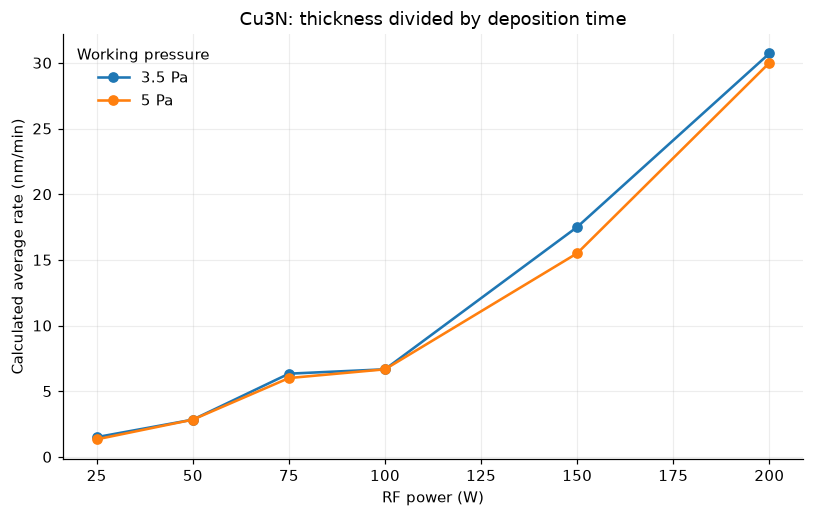

In [6]:
cu = df.loc[df.target_material.eq('Cu3N')].copy()
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for pressure, group in cu.groupby('pressure_Pa'):
    group = group.sort_values('power_W')
    ax.plot(group.power_W, group.calculated_rate_nm_min, marker='o', markersize=6, linewidth=1.7, label=f'{pressure:g} Pa')
ax.set_xlabel('RF power (W)')
ax.set_ylabel('Calculated average rate (nm/min)')
ax.set_title('Cu3N: thickness divided by deposition time')
ax.legend(title='Working pressure', frameon=False)
ax.grid(alpha=0.22)
fig.tight_layout()
fig.savefig(output_dir / '03_cu3n_calculated_rate_by_power.png', bbox_inches='tight')
plt.show()

## 6. Pt：电流、压力与计算平均沉积速率

Pt组没有给出功率，而是报告放电电流。每个点是一条实验记录，点形状区分2 min和12 min；纵轴仍使用 `膜厚 ÷ 时间`。论文另有报告沉积速率字段，两者可能因测量或四舍五入不同，故本图明确标注为计算平均值。

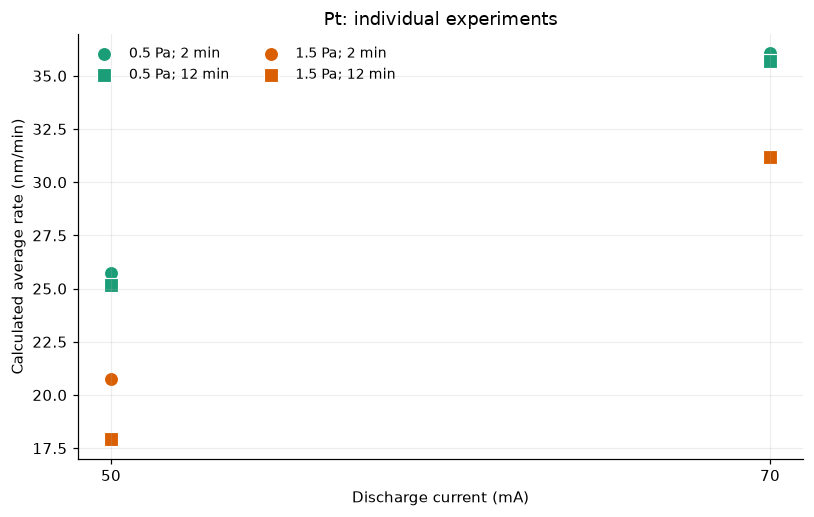

In [7]:
pt = df.loc[df.target_material.eq('Pt')].copy()
fig, ax = plt.subplots(figsize=(7.5, 4.8))
pressure_colors = {0.5: '#1b9e77', 1.5: '#d95f02'}
time_markers = {2: 'o', 12: 's'}
for (pressure, minutes), group in pt.groupby(['pressure_Pa', 'deposition_time_min']):
    ax.scatter(group.discharge_current_mA, group.calculated_rate_nm_min,
               s=85, color=pressure_colors[pressure], marker=time_markers[minutes],
               edgecolor='white', linewidth=0.75, label=f'{pressure:g} Pa; {minutes:g} min')
ax.set_xticks(sorted(pt.discharge_current_mA.unique()))
ax.set_xlabel('Discharge current (mA)')
ax.set_ylabel('Calculated average rate (nm/min)')
ax.set_title('Pt: individual experiments')
ax.legend(frameon=False, fontsize=9, ncol=2)
ax.grid(alpha=0.22)
fig.tight_layout()
fig.savefig(output_dir / '04_pt_calculated_rate_by_current.png', bbox_inches='tight')
plt.show()

## 7. 本轮可直接用于报告的观察

- 主数据包含30条实测记录，分布于Cu₃N（12）、Pt（8）、Ti（9）、W（1）四组。W只有一个样品，适合记录展示，不适合组内趋势分析。
- Ti组的9条记录构成3×3的功率—压力实验矩阵，且沉积时间固定为30 min，因此适合演示参数与膜厚的直观对应。
- Cu₃N组沉积时间并不恒定，因此使用计算平均速率进行描述；Pt组使用电流而非功率。
- 图表只能说明这些论文在各自实验条件下的记录分布。下一步建模需要考虑材料、来源和样本量，并用适当验证方法评估预测误差。

输出文件：`descriptive_summary_by_material.csv` 和4张PNG图，均保存在主数据旁的 `eda` 文件夹。